# Same-initialization student distillation — results

Live analysis of `outputs/students/`, scoped by default to the July 2026 **same-initialization** treatment for **`dog`** on the original **`pythia-160m`** base: teacher and student share the `pythia-160m` checkpoint, the numbers are `ex10-20_prefix` (100k candidate pool, 10 000 trained rows), and both fine-tuning seeds are 1. Section 5 steps aside to the `cat` runs — the only base with a matched PolyPythia re-run — to isolate a base-model effect.

The notebook visualizes run coverage, held-out transfer versus trained controls, student-epoch dose response, seed-matched teacher→student association, teacher hyperparameters, specificity/OOD behavior, and the top configurations.

> **Uncertainty warning.** Current treatment summaries contain one student seed. Persisted across-seed CIs therefore collapse to the point estimate. Spread across teacher configurations below is descriptive, not repeated-seed uncertainty.

> **Student-eval coverage.** The `dog` `pythia-160m` students were scored on `test` and `storytelling` only — the `off_topic`, `validation`, and `dislike` student prompt sets were not run for this base. Panels that depend on those sets (the specificity/off-topic view) therefore render empty; the teacher-side association still works because the teacher's own `validation` score is read directly. Backfill the student evals to repopulate them.

## Setup and artifact loader

Run from the repo root with `uv run --group analysis jupyter lab`. The loader joins every student to its training manifest and to the exact teacher seed that generated its number dataset.

In [ ]:
from __future__ import annotations
import json, re
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import yaml
from IPython.display import display
from scipy.stats import spearmanr

ROOT = Path.cwd()
if not (ROOT / "src").exists() and (ROOT.parent / "src").exists(): ROOT = ROOT.parent
OUTPUT_ROOT = Path(yaml.safe_load((ROOT / "configs/paths/paths_local.yaml").read_text())["output_root"])
STUDENTS_ROOT = OUTPUT_ROOT / "students"
# Sections 1-4 scope: dog on the original pythia-160m base, teacher/ft seed 1. (Section 5 reaches into cat directly.)
SAME_INIT_ANIMAL, SAME_INIT_MODEL, TEACHER_SEED, STUDENT_SEED = "dog", "pythia-160m", 1, 1
# Dataset dirs carry a candidate-pool suffix (_n40k / _n100k); both train 10 000 rows. dog uses the 100k prefix pool.
LABEL = {"ex10-20_prefix_n100k":"prefix (100k pool)", "ex10-20_prefix_n40k":"prefix (40k pool)",
         "ex10-20_full10":"full10", "ex10-20_full10_3digit":"full10, 3-digit"}
COLOR = {"ex10-20_prefix_n100k":"#4c78a8", "ex10-20_prefix_n40k":"#4c78a8",
         "ex10-20_full10":"#f58518", "ex10-20_full10_3digit":"#54a24b"}
plt.rcParams.update({"figure.dpi":115, "axes.grid":True, "grid.alpha":.25, "axes.spines.top":False, "axes.spines.right":False})
print("output_root:", OUTPUT_ROOT)

output_root: /mnt/ssd-2/soar-subliminal/angela/outputs


In [24]:
PARAM_RE = re.compile(r"^ep(?P<ep>\d+)_lr(?P<lr>[^_]+)_r(?P<r>\d+)a(?P<a>\d+)$")
LINEAGE_RE = re.compile(r"^from_(?P<tag>ep\d+_lr[^_]+_r\d+a\d+)_tseed(?P<seed>\d+)(?:_nbase-(?P<nbase>.+))?$")

def read(path): return json.loads(path.read_text())
def tag_fields(tag, prefix):
    m = PARAM_RE.fullmatch(tag)
    if not m: raise ValueError(f"unrecognized parameter tag: {tag}")
    return {f"{prefix}_epochs":int(m["ep"]), f"{prefix}_lr":float(m["lr"]),
            f"{prefix}_rank":int(m["r"]), f"{prefix}_alpha":int(m["a"])}

def metric_rows(doc, meta, teacher_sets=None):
    teacher_sets = teacher_sets or {}
    return [{**meta, "set":s["prompt_set"], "scoring":s.get("scoring"), "n_prompts":s.get("n_prompts"),
             "p":s.get("p_target_mean"), "rank":s.get("rank_mean"), "base_p":s.get("base_p_target"),
             "teacher_p":teacher_sets.get(s["prompt_set"], {}).get("p_target")}
            for s in doc.get("summaries", [])]

def load_treatments():
    rows = []
    n_missing_manifest = n_skipped = 0
    for p in sorted(STUDENTS_ROOT.rglob("preference_summary.json")):
        rel = p.relative_to(STUDENTS_ROOT).parts
        if not rel or rel[0] == "controls": continue  # controls handled by load_controls
        if len(rel) != 6: n_skipped += 1; continue
        animal, model, lineage, dataset, student_tag, _ = rel
        m = LINEAGE_RE.fullmatch(lineage)
        if not m: n_skipped += 1; continue
        teacher_tag, tseed = m["tag"], int(m["seed"])
        numbers_base = m["nbase"] or model
        doc = read(p); seeds = tuple(map(int, doc.get("ft_seeds", [])))
        manifest_path = p.parent / f"ftseed{seeds[0]}" / "train_manifest.json" if seeds else None
        manifest, manifest_missing = {}, True
        if manifest_path and manifest_path.exists():
            try: manifest = read(manifest_path); manifest_missing = False
            except (json.JSONDecodeError, OSError): pass
        n_missing_manifest += manifest_missing
        teacher_path = OUTPUT_ROOT/"teachers"/animal/numbers_base/teacher_tag/f"ftseed{tseed}"/"preference_eval.json"
        teacher_doc = read(teacher_path) if teacher_path.exists() else {}
        tsets = teacher_doc.get("sets") or {}
        def tp(name):
            s = tsets.get(name); return s.get("p_target") if isinstance(s, dict) else None
        meta = {"config_id":str(p.parent), "animal":animal, "model":model, "numbers_base":numbers_base,
                "teacher_tag":teacher_tag, "teacher_seed":tseed, "dataset":dataset, "student_tag":student_tag,
                "student_seeds":seeds, "same_init":None if manifest_missing else (numbers_base == model and seeds == (tseed,) and not manifest.get("cross_base", False)),
                # Teacher association signal read straight from the teacher eval (independent of which prompt sets the
                # student was scored on) — the original pythia-160m students share only `test`/`storytelling` with the teacher.
                "teacher_sig_validation":tp("validation"), "teacher_sig_test":tp("test"),
                "n_train":manifest.get("n_train_rows"), "loss":manifest.get("final_train_loss"), "steps":manifest.get("n_train_steps"),
                **tag_fields(teacher_tag,"teacher"), **tag_fields(student_tag,"student")}
        rows += metric_rows(doc, meta, teacher_doc.get("sets"))
    return pd.DataFrame(rows), n_missing_manifest, n_skipped

def load_controls():
    rows = []
    for p in sorted((STUDENTS_ROOT/"controls").rglob("preference_summary.json")):
        rel = p.relative_to(STUDENTS_ROOT/"controls").parts
        if len(rel) != 7 or rel[4] != "eval": continue
        source, model, dataset, student_tag, _, animal, _ = rel
        doc = read(p); seeds = tuple(map(int, doc.get("ft_seeds", [])))
        meta = {"config_id":str(p.parent), "source":source, "animal":animal, "model":model, "dataset":dataset,
                "student_tag":student_tag, "student_seeds":seeds, **tag_fields(student_tag,"student")}
        rows += metric_rows(doc, meta)
    return pd.DataFrame(rows)

treatments_all, n_missing_manifest, n_skipped = load_treatments()
controls_all = load_controls()
# Sections 1-4: dog + original pythia-160m, same-init, teacher/ft seed 1.
same = treatments_all[treatments_all.same_init.eq(True) & treatments_all.animal.eq(SAME_INIT_ANIMAL) & treatments_all.model.eq(SAME_INIT_MODEL) &
                      treatments_all.teacher_seed.eq(TEACHER_SEED) & treatments_all.student_seeds.map(lambda seeds: seeds == (STUDENT_SEED,))].copy()
controls = (controls_all[controls_all.animal.eq(SAME_INIT_ANIMAL) & controls_all.model.eq(SAME_INIT_MODEL) &
                         controls_all.student_seeds.map(lambda seeds: seeds == (STUDENT_SEED,))].copy()
            if len(controls_all) else controls_all)
assert len(same), "selected same-initialization slice is empty"

META = ["config_id","animal","model","teacher_tag","teacher_seed","dataset","student_tag","teacher_epochs","teacher_lr",
        "teacher_rank","teacher_alpha","teacher_sig_validation","teacher_sig_test","student_epochs","student_lr",
        "student_rank","student_alpha","n_train","loss","steps"]
wide = same.drop_duplicates("config_id")[META].set_index("config_id")
for value, prefix in [("p","student_"),("teacher_p","teacher_"),("base_p","untuned_"),("rank","rank_")]:
    wide = wide.join(same.pivot(index="config_id", columns="set", values=value).add_prefix(prefix))
wide = wide.reset_index()
wide["teacher_lora"] = wide.apply(lambda x:f"r{x.teacher_rank}/α{x.teacher_alpha}", axis=1)
wide["lineage"] = wide.apply(lambda x:f"{x.teacher_tag}|t{x.teacher_seed}|{x.dataset}", axis=1)
# Optional student prompt sets. The original pythia-160m students carry only `test` and `storytelling`; ensure the
# richer per-set columns exist (as NaN) so panels degrade to empty instead of raising on a missing column.
for _pref in ("student_", "teacher_", "untuned_", "rank_"):
    for _set in ("test", "off_topic", "validation", "storytelling"):
        _col = f"{_pref}{_set}"
        if _col not in wide.columns: wide[_col] = np.nan
wide["test_minus_offtopic"] = wide.student_test - wide.student_off_topic
# Teacher signal: prefer the teacher's own `test`, else its `validation`, whichever the teacher eval actually scored.
TEACHER_SIGNAL_SET = "test" if wide.teacher_sig_test.notna().any() else "validation"
wide["teacher_signal"] = wide[f"teacher_sig_{TEACHER_SIGNAL_SET}"]

if len(controls):
    cm = controls.drop_duplicates("config_id")[["config_id","source","model","dataset","student_tag","student_epochs"]].set_index("config_id")
    controls_wide = cm.join(controls.pivot(index="config_id", columns="set", values="p").add_prefix("student_")).reset_index()
else: controls_wide = pd.DataFrame()
if n_missing_manifest: print(f"{n_missing_manifest} runs missing train_manifest.json — excluded")
if n_skipped: print(f"{n_skipped} dirs skipped by layout/regex filters")
print(f"{len(wide)} same-init configs ({SAME_INIT_ANIMAL} / {SAME_INIT_MODEL}); {wide.lineage.nunique()} teacher/dataset lineages; {len(controls_wide)} controls")
print("sets:", sorted(same["set"].unique()))

376 same-init configs (dog / pythia-160m); 94 teacher/dataset lineages; 0 controls
sets: ['storytelling', 'test']


## 1. Inventory and held-out transfer

A config is one `(teacher HP × number mode × student epoch)` result. `test` is the main held-out preference metric. Control markers are trained students and appear only where the training dose matches (currently one epoch).

student_epochs,1,2,5,10
prefix (100k pool),94,94,94,94


missing teacher scores by set:


set
test    376
Name: missing, dtype: int64

teacher association signal: validation
training rows: [np.int64(10000)]


/tmp/ipykernel_580401/1365140620.py:28: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend(fontsize=8,loc="upper left")


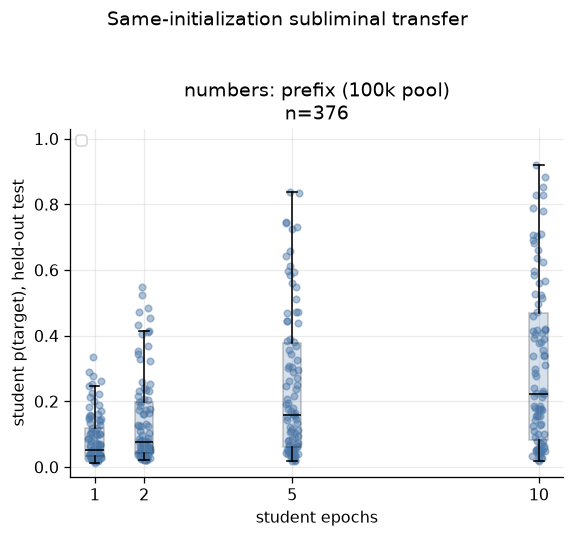

,n,treatment mean,treatment median,base student,mean Δ vs base,rng student,mean Δ vs rng
numbers,,,,,,,
prefix (100k pool),94,0.086,0.051,nan,nan,nan,nan


In [25]:
coverage = pd.crosstab(wide.dataset, wide.student_epochs)
coverage.index = [LABEL.get(x,x) for x in coverage.index]
display(coverage.style.set_caption("Completed same-init configs"))
assert same.duplicated(["config_id","set"]).sum() == 0
print("missing teacher scores by set:")
display(same[same.teacher_p.isna()].groupby("set").size().rename("missing"))
print("teacher association signal:", TEACHER_SIGNAL_SET)
print("training rows:", sorted(wide.n_train.dropna().unique()))

datasets, epochs = sorted(wide.dataset.unique()), sorted(wide.student_epochs.unique())
fig, axs = plt.subplots(1,len(datasets),figsize=(5.1*len(datasets),4.5),sharey=True,squeeze=False)
for ax, ds in zip(axs.ravel(),datasets):
    sub = wide[wide.dataset.eq(ds)]
    groups = [(ep,sub.loc[sub.student_epochs.eq(ep),"student_test"].dropna().values) for ep in epochs]
    groups = [(ep,v) for ep,v in groups if len(v)]
    ax.boxplot([v for _,v in groups],positions=[ep for ep,_ in groups],widths=.38,patch_artist=True,showfliers=False,
               boxprops={"facecolor":COLOR.get(ds,"C0"),"alpha":.22},medianprops={"color":"black"})
    for ep,v in groups:
        jitter = np.linspace(-.13,.13,len(v)) if len(v)>1 else [0]
        ax.scatter(ep+jitter,v,s=17,alpha=.45,color=COLOR.get(ds,"C0"))
    if len(controls_wide):
        for source,marker,color in [("base","D","#e45756"),("rng","^","#72b7b2")]:
            v=controls_wide.loc[controls_wide.dataset.eq(ds)&controls_wide.source.eq(source),"student_test"].dropna()
            if len(v): ax.scatter([1]*len(v),v,marker=marker,s=90,color=color,edgecolor="black",lw=.5,zorder=5,label=f"{source} student (1 ep)")
    base=sub.untuned_test.dropna()
    if len(base): ax.axhline(base.iloc[0],color=".35",ls=":",label="untuned base")
    ax.set(title=f"numbers: {LABEL.get(ds,ds)}\nn={len(sub)}",xlabel="student epochs",xticks=epochs,ylim=(-.03,1.03))
    ax.legend(fontsize=8,loc="upper left")
axs[0,0].set_ylabel("student p(target), held-out test")
fig.suptitle("Same-initialization subliminal transfer",y=1.03); plt.tight_layout(); plt.show()

matched=[]
for ds,sub in wide[wide.student_epochs.eq(1)].groupby("dataset"):
    row={"numbers":LABEL.get(ds,ds),"n":len(sub),"treatment mean":sub.student_test.mean(),"treatment median":sub.student_test.median()}
    for source in ("base","rng"):
        v=controls_wide.loc[controls_wide.dataset.eq(ds)&controls_wide.source.eq(source),"student_test"] if len(controls_wide) else pd.Series(dtype=float)
        assert len(v)<=1, f"multiple {source} controls for dataset {ds}: {v.tolist()}"
        row[f"{source} student"]=v.iloc[0] if len(v) else np.nan
        row[f"mean Δ vs {source}"]=row["treatment mean"]-row[f"{source} student"]
    matched.append(row)
display(pd.DataFrame(matched).set_index("numbers").style.format({c:"{:.3f}" for c in pd.DataFrame(matched).columns if c not in ("numbers","n")}))

## 2. Student dose and teacher → student transfer

Dose-response includes only lineages completed at 1, 2, and 5 epochs. Shaded intervals describe cross-config variation, not seed uncertainty. The teacher signal is read straight from the source teacher's own eval — teacher `test` when available, otherwise teacher `validation` (the teacher artifacts carry no `test` set); student `test` remains the outcome. Spearman's ρ is associative, not causal.

94 complete lineages / 376 students


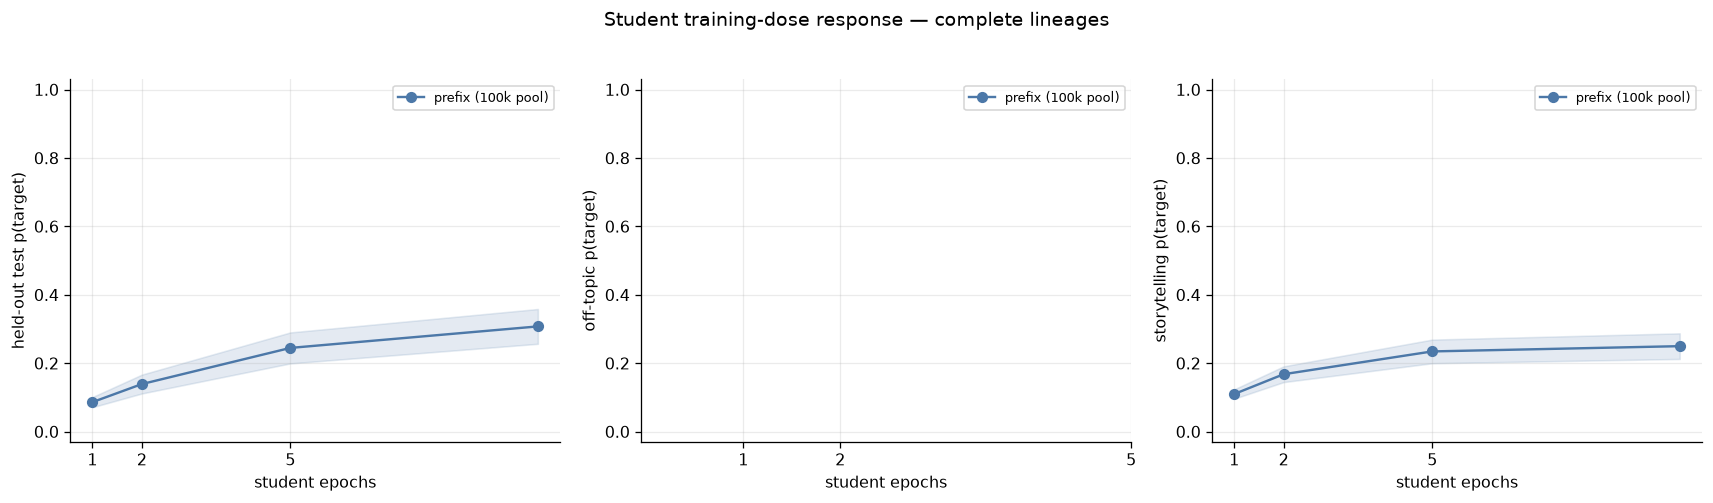

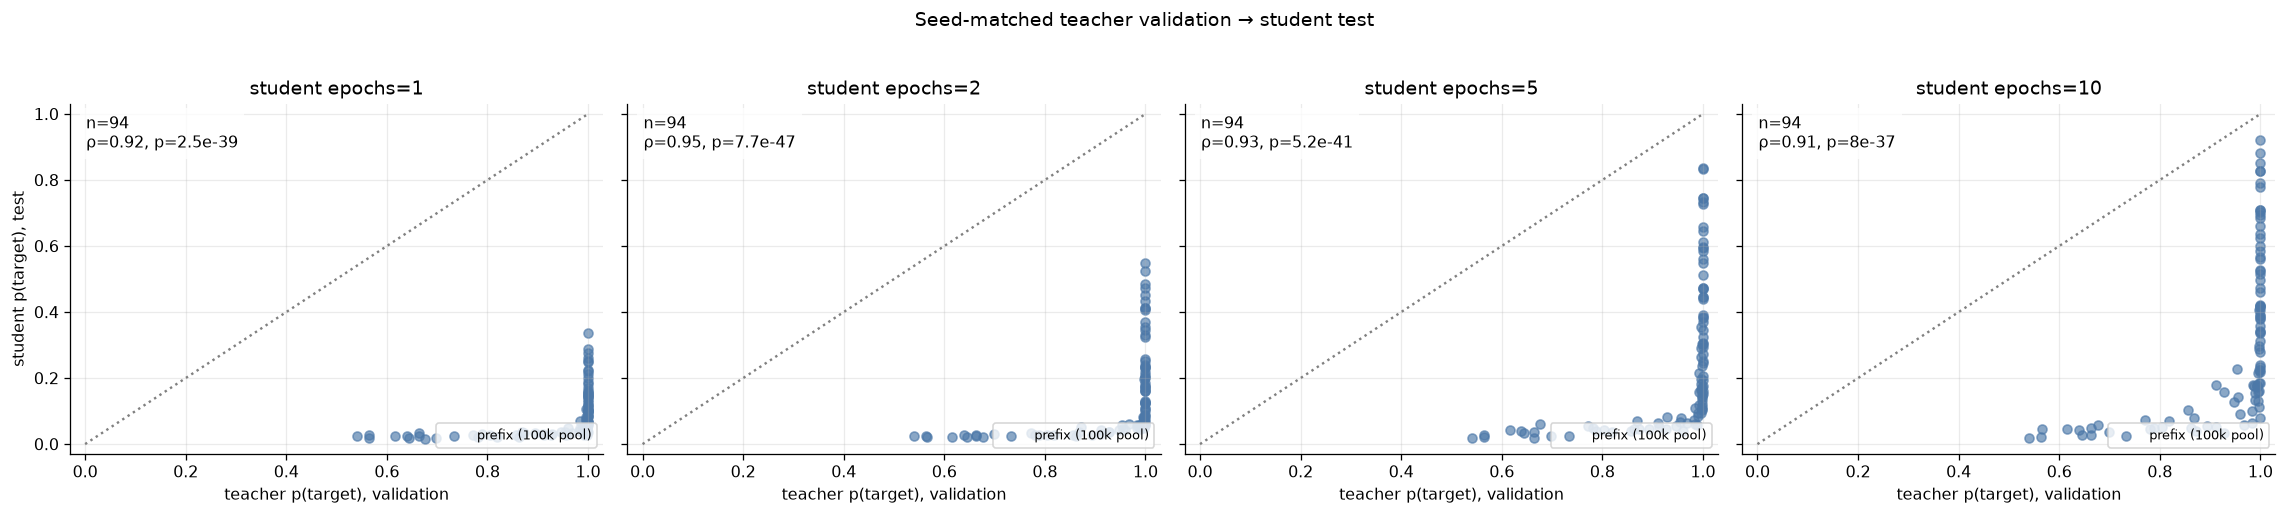

In [26]:
complete = wide.groupby("lineage").student_epochs.agg(lambda x:{1,2,5}.issubset(set(x)))
paired = wide[wide.lineage.isin(complete[complete].index)]
print(f"{paired.lineage.nunique()} complete lineages / {len(paired)} students")
fig,axs=plt.subplots(1,3,figsize=(15,4.2))
for ax,(metric,label) in zip(axs,[("student_test","held-out test"),("student_off_topic","off-topic"),("student_storytelling","storytelling")]):
    for ds,sub in paired.groupby("dataset"):
        s=sub.groupby("student_epochs")[metric].agg(["mean","std","count"]).sort_index(); e=1.96*s["std"].fillna(0)/np.sqrt(s["count"])
        ax.plot(s.index,s["mean"],marker="o",color=COLOR.get(ds),label=LABEL.get(ds,ds)); ax.fill_between(s.index,s["mean"]-e,s["mean"]+e,color=COLOR.get(ds),alpha=.15)
    ax.set(xlabel="student epochs",ylabel=f"{label} p(target)",xticks=[1,2,5],ylim=(-.03,1.03)); ax.legend(fontsize=8)
fig.suptitle("Student training-dose response — complete lineages",y=1.03); plt.tight_layout(); plt.show()

fig,axs=plt.subplots(1,len(epochs),figsize=(5*len(epochs),4.3),sharex=True,sharey=True,squeeze=False)
for ax,ep in zip(axs.ravel(),epochs):
    sub=wide[wide.student_epochs.eq(ep)].dropna(subset=["teacher_signal","student_test"])
    for ds,d in sub.groupby("dataset"): ax.scatter(d.teacher_signal,d.student_test,s=32,alpha=.65,color=COLOR.get(ds),label=LABEL.get(ds,ds))
    rho,p=spearmanr(sub.teacher_signal,sub.student_test) if len(sub)>2 else (np.nan,np.nan); ax.plot([0,1],[0,1],color=".5",ls=":")
    ax.text(.03,.97,f"n={len(sub)}\nρ={rho:.2f}, p={p:.2g}",transform=ax.transAxes,va="top",bbox={"facecolor":"white","alpha":.8,"edgecolor":"none"})
    ax.set(title=f"student epochs={ep}",xlabel=f"teacher p(target), {TEACHER_SIGNAL_SET}",xlim=(-.03,1.03),ylim=(-.03,1.03)); ax.legend(fontsize=8,loc="lower right")
axs[0,0].set_ylabel("student p(target), test"); fig.suptitle(f"Seed-matched teacher {TEACHER_SIGNAL_SET} → student test",y=1.03); plt.tight_layout(); plt.show()

## 3. Teacher hyperparameter surface

Edit the two choices. One figure per animal (here just `dog`); within a figure each populated cell is a single teacher run — a duplicate-key assert on `(animal, teacher_epochs, teacher_lora, teacher_lr)` guarantees no pooling across runs. Rank/alpha and learning rate remain explicit.

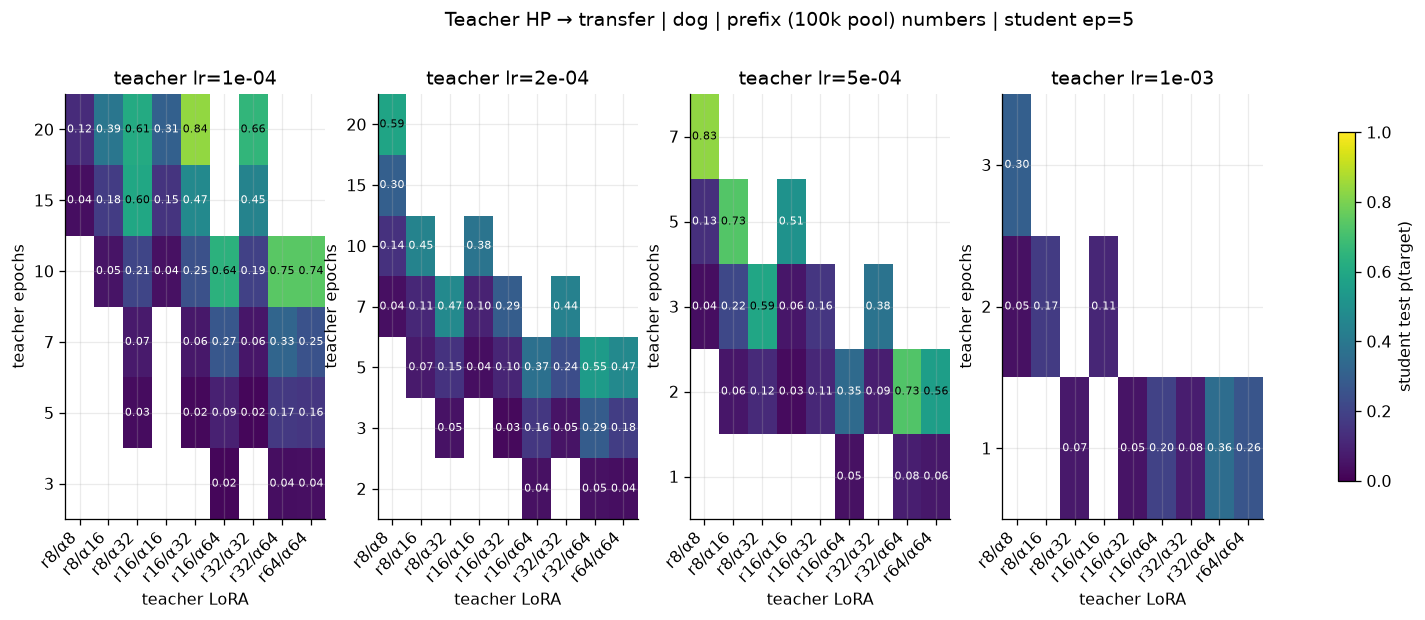

In [27]:
PRIMARY_DATASET, PRIMARY_STUDENT_EPOCH = "ex10-20_prefix_n100k", 5
hp=wide[wide.dataset.eq(PRIMARY_DATASET)&wide.student_epochs.eq(PRIMARY_STUDENT_EPOCH)]
assert len(hp)
DUP_KEYS=["animal","teacher_epochs","teacher_lora","teacher_lr"]
assert not hp.duplicated(DUP_KEYS).any(), \
    f"duplicate teacher-HP keys would pool multiple runs per heatmap cell: {hp[hp.duplicated(DUP_KEYS,keep=False)][DUP_KEYS].to_dict('records')}"
loras=sorted(hp.teacher_lora.unique(),key=lambda x:tuple(map(int,re.findall(r"\d+",x))))
for animal in sorted(hp.animal.unique()):
    ha=hp[hp.animal.eq(animal)]; lrs=sorted(ha.teacher_lr.unique())
    fig,axs=plt.subplots(1,len(lrs),figsize=(4.2*len(lrs),4.8),squeeze=False); image=None
    for ax,lr in zip(axs.ravel(),lrs):
        q=ha[ha.teacher_lr.eq(lr)].pivot(index="teacher_epochs",columns="teacher_lora",values="student_test").reindex(columns=loras)
        image=ax.imshow(q.values,aspect="auto",origin="lower",cmap="viridis",vmin=0,vmax=1)
        ax.set(xticks=range(len(q.columns)),yticks=range(len(q.index)),xlabel="teacher LoRA",ylabel="teacher epochs",title=f"teacher lr={lr:.0e}")
        ax.set_xticklabels(q.columns,rotation=45,ha="right"); ax.set_yticklabels(q.index)
        for i in range(q.shape[0]):
            for j in range(q.shape[1]):
                v=q.iloc[i,j]
                if pd.notna(v): ax.text(j,i,f"{v:.2f}",ha="center",va="center",fontsize=7,color="white" if v<.55 else "black")
    fig.colorbar(image,ax=axs.ravel().tolist(),label="student test p(target)",shrink=.82)
    fig.suptitle(f"Teacher HP → transfer | {animal} | {LABEL.get(PRIMARY_DATASET)} numbers | student ep={PRIMARY_STUDENT_EPOCH}",y=1.03); plt.show()

## 4. Specificity, OOD behavior, and ranked configs

High `test` with low `off_topic` is more specific. Storytelling is sampled and may be read as OOD generalization or leakage. The table's transparent ranking score is `test − off_topic`, not a definitive objective.

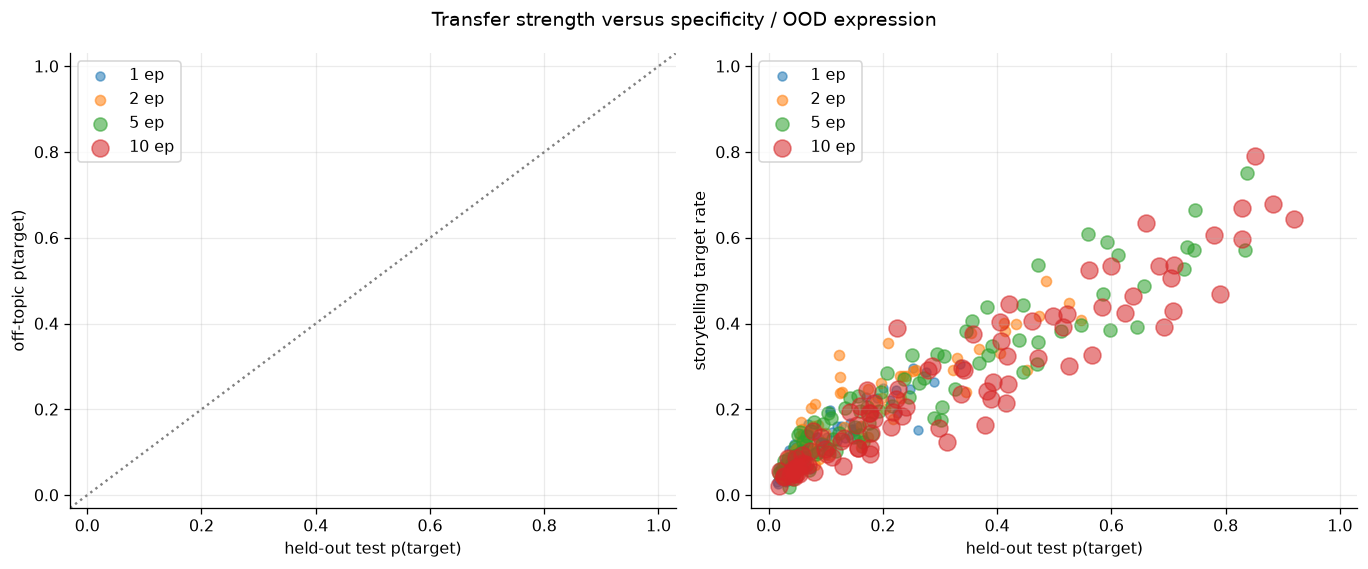

,teacher_tag,dataset,student ep,teacher validation,student_test,student_validation,student_off_topic,student_storytelling,test_minus_offtopic,test rank,loss
112,ep20_lr1e-4_r16a32,ex10-20_prefix_n100k,10,1.000,0.920,nan,nan,0.645,nan,1.0,1.781
372,ep7_lr5e-4_r8a8,ex10-20_prefix_n100k,10,1.000,0.883,nan,nan,0.679,nan,1.0,1.908
316,ep5_lr5e-4_r8a16,ex10-20_prefix_n100k,10,1.000,0.852,nan,nan,0.791,nan,1.0,1.781
115,ep20_lr1e-4_r16a32,ex10-20_prefix_n100k,5,1.000,0.838,nan,nan,0.751,nan,1.0,2.017
375,ep7_lr5e-4_r8a8,ex10-20_prefix_n100k,5,1.000,0.835,nan,nan,0.572,nan,1.0,1.985
300,ep5_lr2e-4_r64a64,ex10-20_prefix_n100k,10,1.000,0.828,nan,nan,0.671,nan,1.0,1.985
116,ep20_lr1e-4_r32a32,ex10-20_prefix_n100k,10,1.000,0.828,nan,nan,0.598,nan,1.0,1.756
20,ep10_lr1e-4_r64a64,ex10-20_prefix_n100k,10,1.000,0.791,nan,nan,0.468,nan,1.0,1.880
312,ep5_lr5e-4_r16a16,ex10-20_prefix_n100k,10,1.000,0.780,nan,nan,0.606,nan,1.0,1.811
19,ep10_lr1e-4_r32a64,ex10-20_prefix_n100k,5,1.000,0.746,nan,nan,0.664,nan,1.0,2.040


,count,mean,median
student_epochs,,,
1,94,0.086,0.051
2,94,0.139,0.078
5,94,0.245,0.160
10,94,0.308,0.224


Overall teacher validation ↔ student test association: ρ=0.834, p=1.56e-98
Best test−off-topic: ep20_lr1e-4_r16a32, prefix (100k pool), student ep=10, test=0.920, off-topic=nan, storytelling=0.645


In [28]:
fig,axs=plt.subplots(1,2,figsize=(12,5))
for ax,y,label in [(axs[0],"student_off_topic","off-topic p(target)"),(axs[1],"student_storytelling","storytelling target rate")]:
    for ep,sub in wide.groupby("student_epochs"): ax.scatter(sub.student_test,sub[y],s=22+9*ep,alpha=.55,label=f"{ep} ep")
    ax.set(xlabel="held-out test p(target)",ylabel=label,xlim=(-.03,1.03),ylim=(-.03,1.03)); ax.legend()
axs[0].axline((0,0),slope=1,color=".5",ls=":"); fig.suptitle("Transfer strength versus specificity / OOD expression"); plt.tight_layout(); plt.show()

cols=["teacher_tag","dataset","student_epochs","teacher_signal","student_test","student_validation","student_off_topic","student_storytelling","test_minus_offtopic","rank_test","loss"]
top=wide.sort_values(["test_minus_offtopic","student_test"],ascending=False)[cols].head(25).rename(columns={"student_epochs":"student ep","rank_test":"test rank","teacher_signal":f"teacher {TEACHER_SIGNAL_SET}"})
formats={c:"{:.3f}" for c in [f"teacher {TEACHER_SIGNAL_SET}","student_test","student_validation","student_off_topic","student_storytelling","test_minus_offtopic","loss"]}; formats["test rank"]="{:.1f}"
display(top.style.format(formats))

best=wide.sort_values(["test_minus_offtopic","student_test"],ascending=False).iloc[0]
dose=wide.groupby("student_epochs").student_test.agg(["count","mean","median"])
rho,p=spearmanr(wide.teacher_signal,wide.student_test,nan_policy="omit")
display(dose.style.format({"mean":"{:.3f}","median":"{:.3f}"}))
print(f"Overall teacher {TEACHER_SIGNAL_SET} ↔ student test association: ρ={rho:.3f}, p={p:.3g}")
print(f"Best test−off-topic: {best.teacher_tag}, {LABEL.get(best.dataset,best.dataset)}, student ep={best.student_epochs:g}, test={best.student_test:.3f}, off-topic={best.student_off_topic:.3f}, storytelling={best.student_storytelling:.3f}")

## 5. Does the base checkpoint set same-init transfer strength? (`cat`, `pythia-160m` vs `pythia-160m-data-seed1`)

Sections 1–4 are scoped to `dog` + the original `pythia-160m`. This section steps sideways to the **`cat`** runs, the only subject where the original `pythia-160m` has a matched PolyPythia re-run (`data-seed1`) to compare against. The question: is same-init transfer strength a property of the *base checkpoint* — or of what happened to be run? The two bases weren't run identically (`data-seed1` also spans `full10`/`full10_3digit`, and its prefix numbers were drawn from a larger candidate pool), so pooling them naively is apples-to-oranges.

This section makes the comparison **fair** by matching everything mechanical and letting only the base model vary:

- **number mode** fixed to the `ex10-20_prefix` template — both bases train on **10 000** prefix rows (the candidate pools differ, 40k for the original vs 100k for `data-seed1`, but the trained row count and format are identical),
- **teacher HP grid** intersected (only teacher configs run for *both* bases),
- **student dose** compared epoch-by-epoch,
- **student LoRA** identical (`lr1e-4_r8a32`), **teacher seed 1 / ft seed 1**, both **same-init** (student initialized from the same checkpoint that generated its numbers).

The two right-hand panels are **controls**: the teacher's own trait strength (are the teachers equally good?) and the student's final train loss (did `pythia-160m` just fail to fit the numbers?). If both controls match, the residual gap is a genuine base-model / pretraining-run effect on the covert number→preference channel.

configs per base: {'pythia-160m': 336, 'pythia-160m-data-seed1': 255} | shared teacher HPs: 67
candidate pool per base: {'pythia-160m': ['ex10-20_prefix_n40k'], 'pythia-160m-data-seed1': ['ex10-20_prefix_n100k']} | trained rows: [np.int64(10000)]


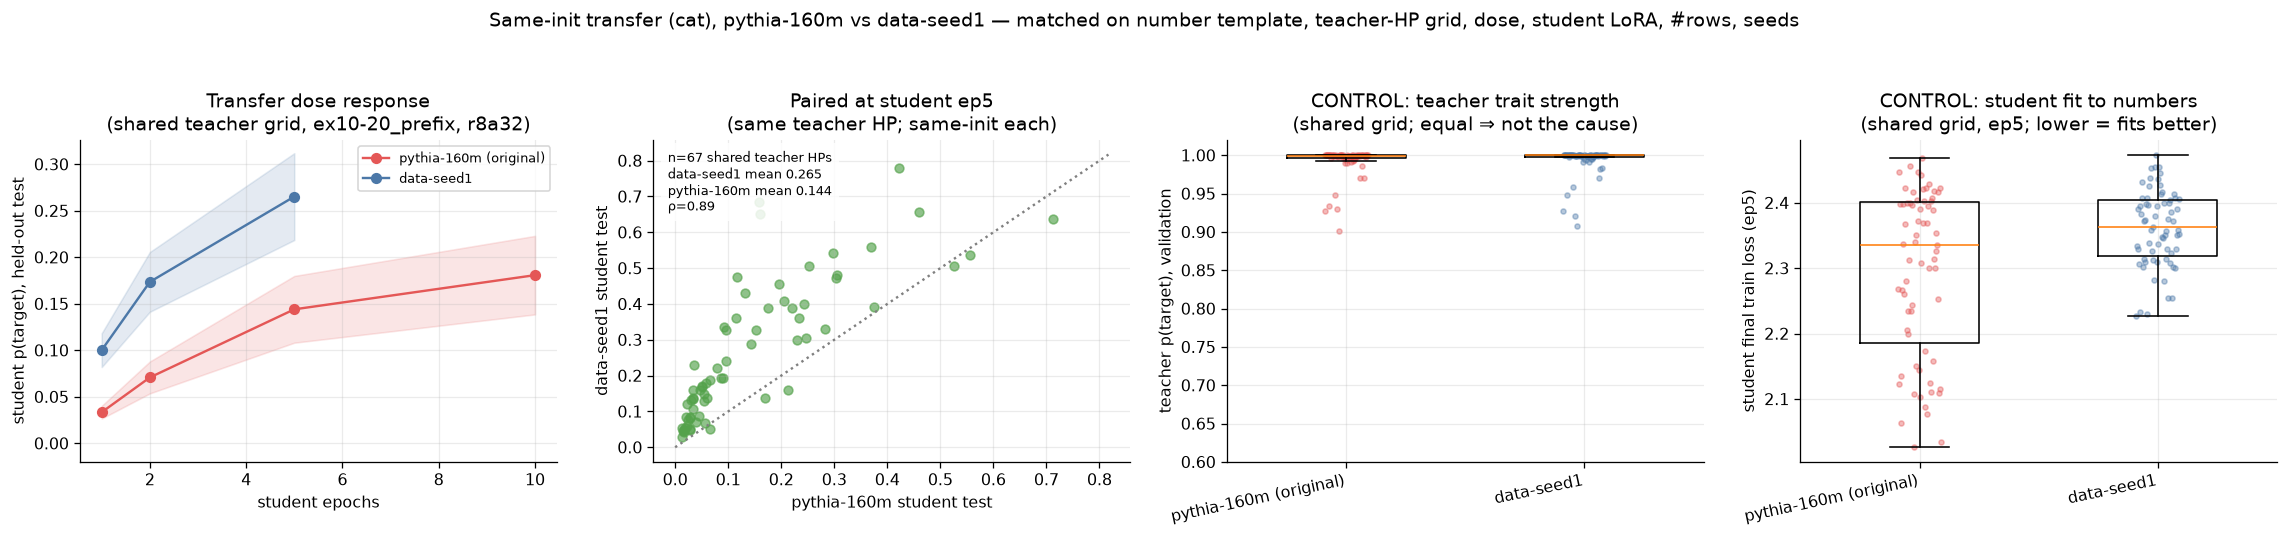

,n shared teacher HP,pythia-160m mean,data-seed1 mean,ratio 160m/seed1,paired Δ (160m−seed1)
student ep,,,,,
1,67,0.033,0.100,0.334,-0.067
2,67,0.071,0.174,0.408,-0.103
5,67,0.144,0.265,0.543,-0.121


CONTROLS on the shared grid — why the gap is not an artifact:
  teacher validation p(target):  pythia-160m=0.992  data-seed1=0.993   (teachers equally trait-loaded on the matched grid)
  student final train loss (ep5): pythia-160m=2.295  data-seed1=2.361   (pythia-160m fits the numbers at least as well)
  matched on: number template=ex10-20_prefix (pools n40k vs n100k, 10000 trained rows), student LoRA=r8a32/lr1e-4, tseed1/ftseed1, same-init


In [29]:
# Compare same-init transfer for two bases (cat), matched on everything mechanical so only the base model differs.
CMP_ANIMAL = "cat"   # the only subject with both the original pythia-160m and its data-seed1 re-run
CMP_BASES = ["pythia-160m", "pythia-160m-data-seed1"]
BASE_NAME = {"pythia-160m":"pythia-160m (original)", "pythia-160m-data-seed1":"data-seed1"}
BASE_C    = {"pythia-160m":"#e45756", "pythia-160m-data-seed1":"#4c78a8"}
CMP_MODE  = "ex10-20_prefix"   # match on the prefix template; the two bases differ only in candidate pool (n40k vs n100k), both train 10k rows
A, B      = "pythia-160m", "pythia-160m-data-seed1"

t = treatments_all
c = t[t["set"].eq("test") & t.same_init.eq(True) & t.animal.eq(CMP_ANIMAL) & t.teacher_seed.eq(TEACHER_SEED) &
      t.student_seeds.map(lambda s: s == (STUDENT_SEED,)) & t.dataset.str.startswith(CMP_MODE) &
      t.student_rank.eq(8) & t.student_alpha.eq(32) & np.isclose(t.student_lr, 1e-4) &
      t.model.isin(CMP_BASES)].drop_duplicates("config_id").rename(columns={"p":"student_test"}).copy()
present = [b for b in CMP_BASES if b in set(c.model)]
# Teacher HP tags run for BOTH bases (dose-independent) — every matched panel/table below restricts to these.
SHARED = sorted(set(c.loc[c.model.eq(A),"teacher_tag"]) & set(c.loc[c.model.eq(B),"teacher_tag"])) if len(present)==2 else []
print("configs per base:", {b: int(c.model.eq(b).sum()) for b in present}, "| shared teacher HPs:", len(SHARED))
print("candidate pool per base:", {b: sorted(c.loc[c.model.eq(b),"dataset"].unique()) for b in present},
      "| trained rows:", sorted(c.n_train.dropna().unique()))
cs = c[c.teacher_tag.isin(SHARED)]   # matched slice: only teacher HPs run for both bases

fig, axs = plt.subplots(1, 4, figsize=(20, 4.4))

# (A) transfer dose response on the shared teacher grid: mean held-out test vs student epochs, per base
ax = axs[0]
for b in present:
    g = cs[cs.model.eq(b)].groupby("student_epochs").student_test.agg(["mean","std","count"]).sort_index()
    e = 1.96*g["std"].fillna(0)/np.sqrt(g["count"])
    ax.plot(g.index, g["mean"], marker="o", color=BASE_C[b], label=BASE_NAME[b])
    ax.fill_between(g.index, g["mean"]-e, g["mean"]+e, color=BASE_C[b], alpha=.15)
ax.set(xlabel="student epochs", ylabel="student p(target), held-out test",
       title=f"Transfer dose response\n(shared teacher grid, {CMP_MODE}, r8a32)"); ax.legend(fontsize=8); ax.set_ylim(bottom=-.02)

# (B) paired per-teacher-config at ep5 on the shared teacher grid
ax = axs[1]
if len(present) == 2:
    ep = 5
    a  = cs[cs.model.eq(A) & cs.student_epochs.eq(ep)].set_index("teacher_tag").student_test
    bb = cs[cs.model.eq(B) & cs.student_epochs.eq(ep)].set_index("teacher_tag").student_test
    sh = a.index.intersection(bb.index)
    ax.scatter(a[sh], bb[sh], s=30, alpha=.65, color="#54a24b")
    lim = float(max(a[sh].max(), bb[sh].max()))*1.05
    ax.plot([0,lim],[0,lim], color=".5", ls=":")
    rho,_ = spearmanr(a[sh], bb[sh])
    ax.text(.03,.97, f"n={len(sh)} shared teacher HPs\ndata-seed1 mean {bb[sh].mean():.3f}\npythia-160m mean {a[sh].mean():.3f}\nρ={rho:.2f}",
            transform=ax.transAxes, va="top", bbox={"facecolor":"white","alpha":.85,"edgecolor":"none"}, fontsize=8)
    ax.set(xlabel="pythia-160m student test", ylabel="data-seed1 student test",
           title=f"Paired at student ep{ep}\n(same teacher HP; same-init each)")

# (C) CONTROL — teacher trait strength on the SHARED grid (one value per shared teacher HP, dose-independent)
ax = axs[2]
tvals = cs.drop_duplicates(["model","teacher_tag"])
for i,b in enumerate(present):
    v = tvals.loc[tvals.model.eq(b),"teacher_sig_validation"].dropna().values
    ax.boxplot([v], positions=[i], widths=.5, showfliers=False)
    ax.scatter(i + np.linspace(-.09,.09,len(v)), v, s=10, alpha=.4, color=BASE_C[b])
ax.set(xticks=range(len(present)), ylim=(0.6,1.02), ylabel="teacher p(target), validation",
       title="CONTROL: teacher trait strength\n(shared grid; equal ⇒ not the cause)")
ax.set_xticklabels([BASE_NAME[b] for b in present], rotation=12, ha="right")

# (D) CONTROL — student fit at a common dose (ep5) on the shared grid: did pythia-160m under-fit the numbers?
ax = axs[3]
fit = cs[cs.student_epochs.eq(5)]
for i,b in enumerate(present):
    v = fit.loc[fit.model.eq(b),"loss"].dropna().values
    ax.boxplot([v], positions=[i], widths=.5, showfliers=False)
    ax.scatter(i + np.linspace(-.09,.09,len(v)), v, s=10, alpha=.4, color=BASE_C[b])
ax.set(xticks=range(len(present)), ylabel="student final train loss (ep5)",
       title="CONTROL: student fit to numbers\n(shared grid, ep5; lower = fits better)")
ax.set_xticklabels([BASE_NAME[b] for b in present], rotation=12, ha="right")

fig.suptitle(f"Same-init transfer ({CMP_ANIMAL}), pythia-160m vs data-seed1 — matched on number template, teacher-HP grid, dose, student LoRA, #rows, seeds", y=1.05)
plt.tight_layout(); plt.show()

# ---- matched summary on shared teacher HPs, per dose ----
recs = []
for ep in sorted(set(cs[cs.model.eq(A)].student_epochs) & set(cs[cs.model.eq(B)].student_epochs)):
    a  = cs[cs.model.eq(A) & cs.student_epochs.eq(ep)].set_index("teacher_tag").student_test
    bb = cs[cs.model.eq(B) & cs.student_epochs.eq(ep)].set_index("teacher_tag").student_test
    sh = a.index.intersection(bb.index)
    recs.append({"student ep":ep, "n shared teacher HP":len(sh),
                 "pythia-160m mean":a[sh].mean(), "data-seed1 mean":bb[sh].mean(),
                 "ratio 160m/seed1":a[sh].mean()/bb[sh].mean(), "paired Δ (160m−seed1)":(a[sh]-bb[sh]).mean()})
tbl = pd.DataFrame(recs).set_index("student ep")
display(tbl.style.format({k:"{:.3f}" for k in tbl.columns if k!="n shared teacher HP"})
        .set_caption(f"Matched same-init transfer ({CMP_ANIMAL}) on {len(SHARED)} shared teacher HPs ({CMP_MODE}, student r8a32)"))

# Controls computed on the SAME matched slice, so they actually license the "not an artifact" claim.
tv  = lambda b: cs.drop_duplicates(["model","teacher_tag"]).pipe(lambda d: d.loc[d.model.eq(b),"teacher_sig_validation"]).mean()
ls5 = lambda b: fit.loc[fit.model.eq(b),"loss"].mean()
print("CONTROLS on the shared grid — why the gap is not an artifact:")
print(f"  teacher validation p(target):  pythia-160m={tv(A):.3f}  data-seed1={tv(B):.3f}   (teachers equally trait-loaded on the matched grid)")
print(f"  student final train loss (ep5): pythia-160m={ls5(A):.3f}  data-seed1={ls5(B):.3f}   (pythia-160m fits the numbers at least as well)")
print(f"  matched on: number template={CMP_MODE} (pools n40k vs n100k, 10000 trained rows), student LoRA=r8a32/lr1e-4, tseed1/ftseed1, same-init")

### What the comparison shows

**The gap is real and dose-robust.** Matched on the number template, the shared teacher-HP grid, dose, and student LoRA, `data-seed1` transfers ~2–3× more than `pythia-160m` at every student dose (≈0.10 vs 0.03 at ep1, 0.17 vs 0.07 at ep2, 0.27 vs 0.14 at ep5 — `pythia-160m` ≈ 0.3–0.5× of `data-seed1`). In the paired panel almost every point sits **above** the identity line: for the *same* teacher hyperparameters, the `data-seed1` same-init student picks up more of the animal preference.

**It is not a teacher-strength difference.** On the shared grid both teachers reach ≈0.99 validation p(target) — the explicit trait is equally strong in both. What differs is how much of that trait leaks through the number channel, not how much trait the teacher has.

**It is not under-fitting.** `pythia-160m` students reach a *lower* final train loss (they fit the number sequences at least as well), yet transfer less. Weak transfer is therefore not "the student failed to learn the numbers."

**Everything mechanical is held equal** — both bases train on 10 000 `ex10-20_prefix` rows (the candidate pools differ, 40k for the original vs 100k for `data-seed1`, but the trained row count and format are identical), same student LoRA (`r8a32`, `lr1e-4`), teacher seed 1 / ft seed 1, same-init on both sides.

### Why — the likely cause

With teacher trait, number mode, dose, LoRA, data volume, and student fit all controlled, the residual is a **property of the pretrained checkpoint itself**. The original Pythia-160m and the PolyPythia `data-seed1` re-run are *different pretraining trajectories* (a different data-ordering seed), so their internal representation geometry differs.

Read through the steering-vector-distillation account (Blank et al.): subliminal transfer works because the teacher's trait fine-tune induces a direction that bleeds into the number-token logits, and a **same-init** student re-absorbs that direction through gradient alignment on the numbers. How strongly the animal-preference direction is entangled with the number distribution — the *gain* of that covert channel — is set by the base checkpoint's geometry. `data-seed1` evidently has a higher-gain channel than the original Pythia-160m, even though the two models are the same size and the teacher expresses the trait equally. That the `pythia-160m` gap is a *uniform downward shift* across teacher epochs and student doses (rather than a threshold that never fires) is consistent with a channel-gain difference, not a broken pipeline.

### Caveats before over-reading

- **One animal (cat), one teacher seed, one student seed** — these are point estimates; add student/teacher seeds before treating the ~2–3× ratio as precise. (The `dog` same-init runs in Sections 1–4 use the original `pythia-160m` only, with no `data-seed1` counterpart to close the base loop.)
- **`test` only** — `pythia-160m` students were not scored on `off_topic`/`validation`, so specificity isn't controlled here; a backfill would let us check the gap isn't just noisier off-target expression.
- **Untuned baseline not recorded for `pythia-160m`** (`base_p` is NaN; `data-seed1` ≈ 0.005). Both are 160m models trained from scratch so a near-zero baseline is expected, but backfilling the base-control eval would close this off as an alternative explanation.
- **Candidate pools differ** (40k for the original vs 100k for `data-seed1`), though both train the same 10 000 `ex10-20_prefix` rows; the base gap could also differ under `full10` modes, which the original `pythia-160m` hasn't been run on.

### Interpretation checklist

- Use held-out `test`, not teacher-trained `favorite`, for the main transfer claim.
- Report `off_topic` beside `test`; high values on both are not specific.
- Treat `dislike` as a valence/lexical control.
- Compare trained treatment and control students only when number mode, base, epoch dose, and seed policy match.
- Add multiple student seeds before reporting seed-level uncertainty or stable treatment-minus-control intervals.
- Storytelling is sampled and noisier than the exact-probability prompt sets.